# S4b results, step by step: phase cleaning and then inversion (Sim2)

What this notebook shows, in order:

1. **The problem**: the measured field is `b_dirty = D*chi + psi`; `psi` is the non-dipolar part we want to remove.
2. **What `psi` looks like** (amplitude, spectrum, relation to the dipole cone).
3. **The cleaning**: dirty -> cleaned, what the network removed vs the true `psi`, what remains.
4. **Which frequencies each method fixes**, and a comparison with a tuned low-pass filter and the failed runs (tissue, combo).
5. **The inversion**: the same eNDI (`ndiCG_auto`, alpha 1e-5, 150 iterations max, 256^3 padding) applied to every field: susceptibility maps, error maps, convergence.
6. **Why phase error is not enough**: phase NRMSE vs eNDI NRMSE.

Everything is **Sim2 (one volume)**; all models were trained on RC1 only and the checkpoint was chosen on RC1 only. Single seed per run unless said otherwise.

**Data file.** The notebook reads `runs/notebook_data.npz`, made on the GPU server (the eNDI inversions need the GPU):

```bash
cd ~/mcno/MCNO-QSM
nohup .venv/bin/python scripts/export_notebook_data.py --runs noise mix tissue combo --out runs/notebook_data.npz > runs/notebook_data.log 2>&1 &
```
then copy it to `runs/notebook_data.npz` on the PC (`scp`). The notebook itself needs no model and no GPU.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"axes.labelsize": 10, "axes.titlesize": 10, "legend.fontsize": 9,
                     "xtick.labelsize": 8, "ytick.labelsize": 8, "figure.dpi": 110})

import sys
# find the user's FANSI_tools.py (external/ or utils/) and the exported data, looking from here upwards
here = [Path.cwd(), *Path.cwd().parents]
def find(*rel):
    for base in here:
        for r in rel:
            if (base / r).exists():
                return base / r
    raise FileNotFoundError(f"none of {rel} found from {Path.cwd()} or its parents")
sys.path.insert(0, str(find("external/FANSI_tools.py", "utils/FANSI_tools.py", "FANSI_tools.py").parent))
from FANSI_tools import imagesc3d2, compute_rmse            # the user's own plotting / RMSE functions
DATA = find("runs/notebook_data.npz", "notebook_data.npz")  # made by scripts/export_notebook_data.py on the server
print("data:", DATA)
MAIN = "noise"                               # the run examined in detail (best on Sim2)
RUNS = ["noise", "mix", "tissue", "combo"]   # cleaned runs in the file

raw = np.load(DATA)
meta = json.loads(str(raw["meta_json"]))
V = {k: raw[k].astype(np.float32) if raw[k].ndim == 3 else raw[k] for k in raw.files if k != "meta_json"}
mask = V["mask"] > 0
chi_gt, clean, weight = V["chi_gt"], V["clean"], V["weight"]
vox = tuple(float(v) for v in V["voxel_size"])
methods = [m for m in ["dirty", "lowpass"] + RUNS + ["oracle"] if f"field_{m}" in V]
field = {m: V[f"field_{m}"] for m in methods}
chi_hat = {m: V[f"chi_{m}"] for m in methods}
psi = (field["dirty"] - clean) * mask        # true non-dipolar component (in mask)
print("shape", mask.shape, "voxel", vox, "mask fraction %.3f" % mask.mean())
print("methods:", methods)

data: c:\Users\ignac\OneDrive\Desktop\Projects\Research\2025\QSM\DipoleNet\MCNO-QSM\runs\notebook_data.npz
shape (164, 205, 205) voxel (0.9990243911743164, 0.9990243911743164, 0.9990243911743164) mask fraction 0.170
methods: ['dirty', 'lowpass', 'noise', 'mix', 'tissue', 'combo', 'oracle']


In [2]:
# ---------------- helpers ----------------
idx = np.argwhere(mask)
lo, hi = idx.min(0), idx.max(0) + 1
centre = idx.mean(0).astype(int)

ROT = [90, 90, 90]      # rotation of the three views, as in the Dipole-lets paper plots (adjust if a view is upside down)

def show(vols, titles, vmin, vmax, cmap="gray", planes=None, label=None, size=None, pos=None):
    # one imagesc3d2 figure (axial/coronal/sagittal through `pos`) per volume, same contrast for all
    pos = tuple(centre) if pos is None else pos
    for v, t in zip(vols, titles):
        imagesc3d2(v, pos, cmap=cmap, contrast=[vmin, vmax], fig_num=1, rot_deg=ROT, scale_fig=[-0.12, 0.12, -0.12, 0.12],
                   avg_size=0, title_fig=f"{t.replace(chr(10), ' ')}  [{vmin:.3g}, {vmax:.3g}]")

def nrmse(a, b):
    return compute_rmse(mask * a, mask * b)      # FANSI_tools convention (percent)

# dipole kernel (B0 || z, aligned for odd N too) and |k| in cycles/mm
ks = [np.fft.fftfreq(n, d=v) for n, v in zip(mask.shape, vox)]
KX, KY, KZ = np.meshgrid(*ks, indexing="ij")
K2 = KX**2 + KY**2 + KZ**2
D = 1 / 3 - KZ**2 / np.where(K2 == 0, 1, K2); D[0, 0, 0] = 0
KR = np.sqrt(K2)

def power(vol):
    return np.abs(np.fft.fftn(vol * mask)) ** 2

def radial_spectrum(vol, bins=40, kmax=0.5):
    P = power(vol)
    edges = np.linspace(0, kmax, bins + 1)
    which = np.digitize(KR.ravel(), edges) - 1
    ok = (which >= 0) & (which < bins)
    s = np.bincount(which[ok], P.ravel()[ok], minlength=bins) / np.maximum(np.bincount(which[ok], minlength=bins), 1)
    return 0.5 * (edges[1:] + edges[:-1]), s

def energy_fraction(vol, sel):
    P = power(vol)
    return P[sel].sum() / P.sum()

def band_power(vol, sel):
    return power(vol)[sel].sum()

## 0. Summary table (Sim2, masked protocol)

In [3]:
print(f"{'method':10s} {'phase NRMSE':>12s} {'eNDI NRMSE':>11s} {'XSIM':>7s} {'stop':>5s}")
for m in methods:
    r = meta[m]
    print(f"{m:10s} {r['phase_nrmse']:11.2f}% {r['endi_nrmse']:10.2f}% {r['xsim']:7.4f} {r['stop']:5d}")

method      phase NRMSE  eNDI NRMSE    XSIM  stop
dirty            42.24%      52.60%  0.4969    16
lowpass          28.99%      49.03%  0.5253    16
noise            26.26%      46.96%  0.5557    27
mix              27.18%      48.78%  0.5465    53
tissue           37.44%      60.60%  0.3930    31
combo            39.03%      53.34%  0.4824    21
oracle            0.00%      44.22%  0.5826    20


## 1. The problem: `b_dirty = D*chi + psi`

* `chi`: ground-truth susceptibility. `clean = mask * D*chi`: the field we *want* (the training target).
* `dirty`: Sim2's `Frequency` (ppm): what we *have*. `psi = dirty - clean` is what the cleaner should remove.

The colour scale is shared inside each figure, so amplitudes are comparable.

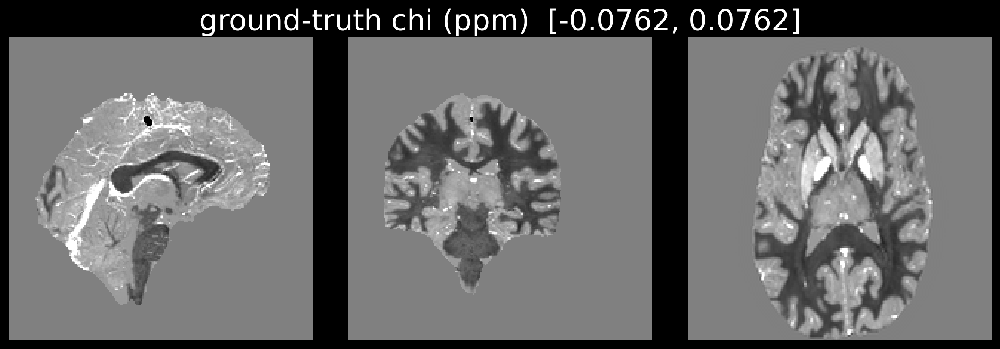

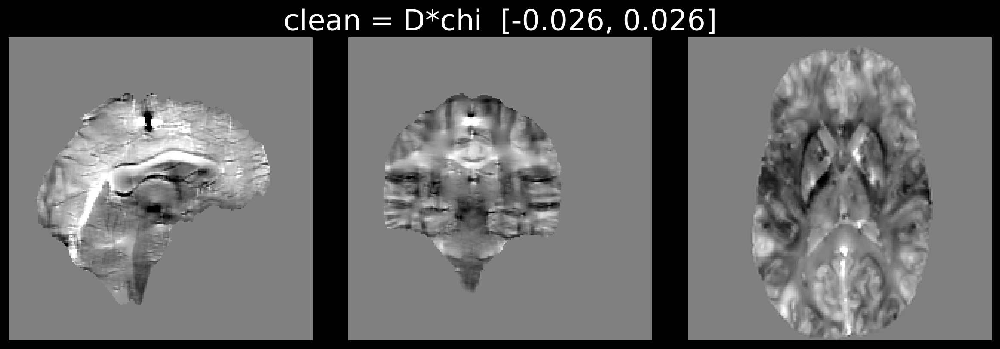

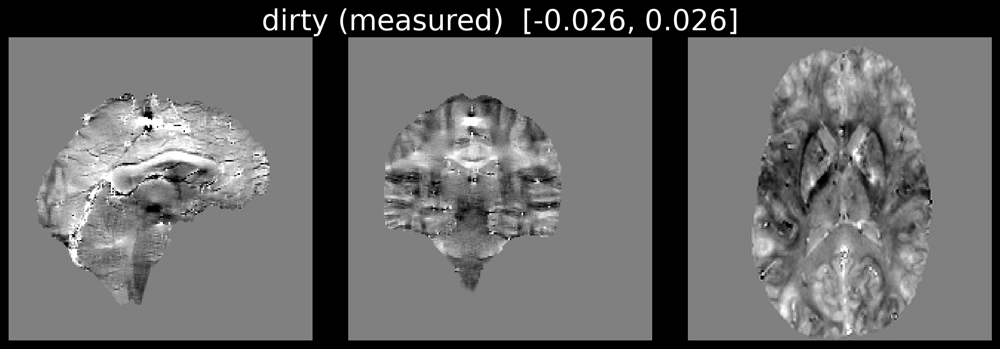

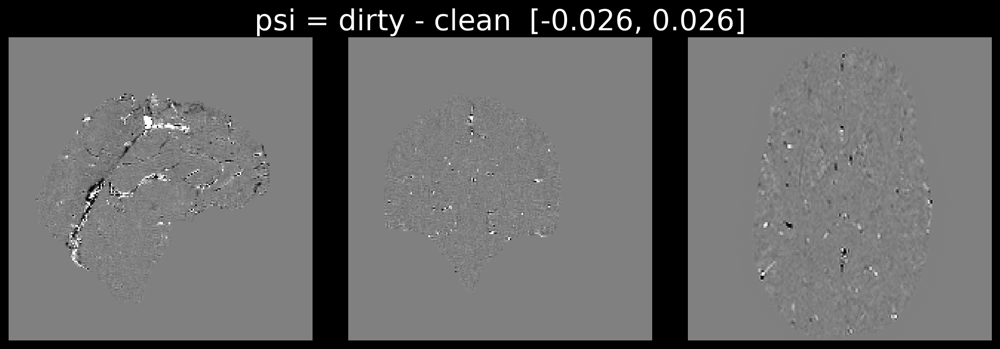

rms in mask: clean 0.0088 ppm, psi 0.0037 ppm, psi/clean = 0.42


In [6]:
lim = np.percentile(np.abs(chi_gt[mask]), 99)
show([chi_gt * mask], ["ground-truth chi (ppm)"], -lim, lim)
a = np.percentile(np.abs(clean[mask]), 99)
show([clean, field["dirty"], psi], ["clean = D*chi", "dirty (measured)", "psi = dirty - clean"], -a, a)
rms = lambda x: np.sqrt((x[mask] ** 2).mean())
print("rms in mask: clean %.4f ppm, psi %.4f ppm, psi/clean = %.2f" % (rms(clean), rms(psi), rms(psi) / rms(clean)))

## 2. What `psi` looks like

Left: amplitude distribution (heavy tails). Middle: power per radial frequency: `psi` is spread over high frequencies while the clean field is smooth. Right: the dipole kernel `D` in the kx-kz plane (B0 along the vertical axis): the "magic cone" `|D| ~ 0` is where the field carries almost no information on `chi`.

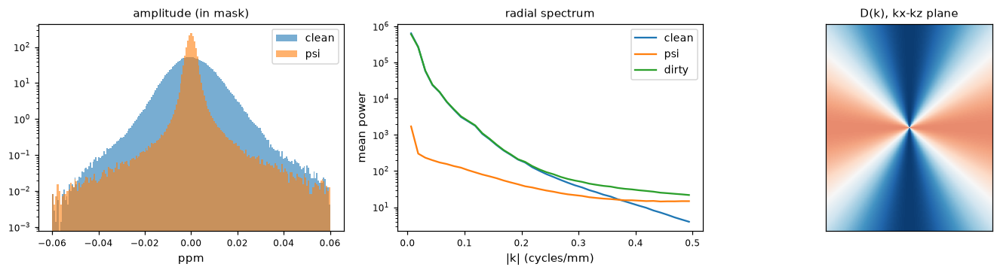

power with |D|<0.03 (7.3% of k-space): clean 0.35%, psi 4.79%, dirty 1.04%
psi power above 0.2 cycles/mm: 84.7%


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
ax[0].hist(clean[mask], bins=200, range=(-0.06, 0.06), alpha=.6, label="clean", density=True)
ax[0].hist(psi[mask], bins=200, range=(-0.06, 0.06), alpha=.6, label="psi", density=True)
ax[0].set_yscale("log"); ax[0].set_xlabel("ppm"); ax[0].legend(); ax[0].set_title("amplitude (in mask)")
for name, vol in [("clean", clean), ("psi", psi), ("dirty", field["dirty"])]:
    k, s = radial_spectrum(vol); ax[1].semilogy(k, s, label=name)
ax[1].set_xlabel("|k| (cycles/mm)"); ax[1].set_ylabel("mean power"); ax[1].legend(); ax[1].set_title("radial spectrum")
ax[2].imshow(np.fft.fftshift(D[:, 0, :]).T, cmap="RdBu_r", vmin=-.7, vmax=.7, origin="lower")
ax[2].set_title("D(k), kx-kz plane"); ax[2].set_xticks([]); ax[2].set_yticks([])
plt.tight_layout(); plt.show()
cone = np.abs(D) < 0.03
print("power with |D|<0.03 (%.1f%% of k-space): clean %.2f%%, psi %.2f%%, dirty %.2f%%" % (
    100 * cone.mean(), 100 * energy_fraction(clean, cone), 100 * energy_fraction(psi, cone), 100 * energy_fraction(field["dirty"], cone)))
print("psi power above 0.2 cycles/mm: %.1f%%" % (100 * energy_fraction(psi, KR > 0.2)))

## 3. The cleaning step (main run)

The network predicts the artifact `n_hat` and returns `cleaned = mask * (dirty - n_hat)`. For the run `MAIN`:

* **removed** `= dirty - cleaned` (the network's estimate of `psi`),
* **true psi**, and **remaining error** `= cleaned - clean` (the dirty field's error is `psi` itself).

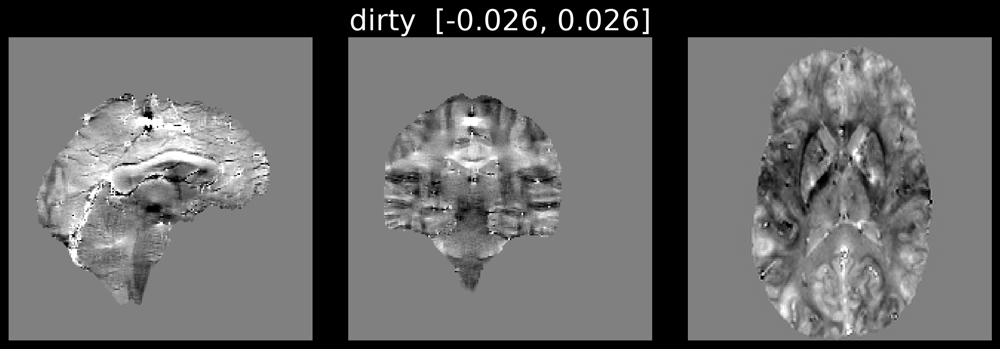

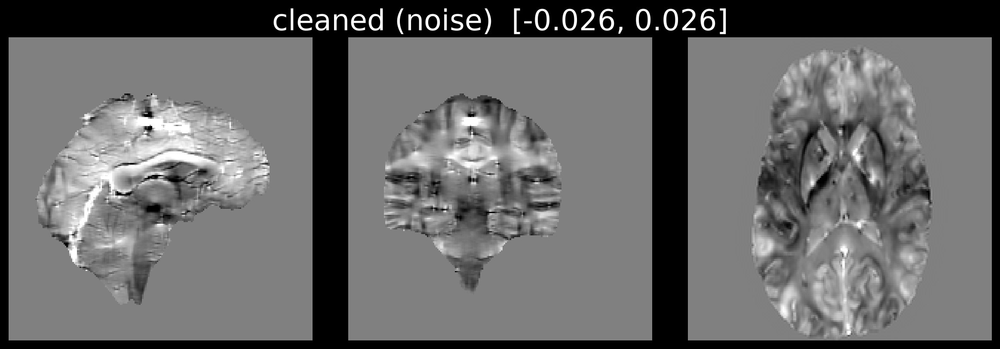

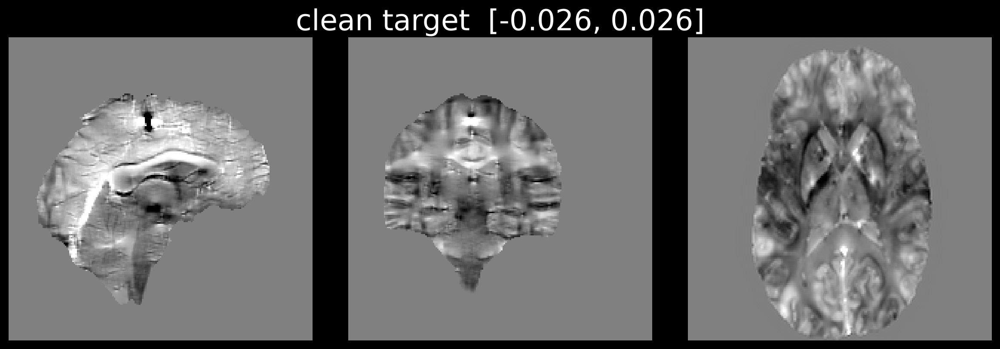

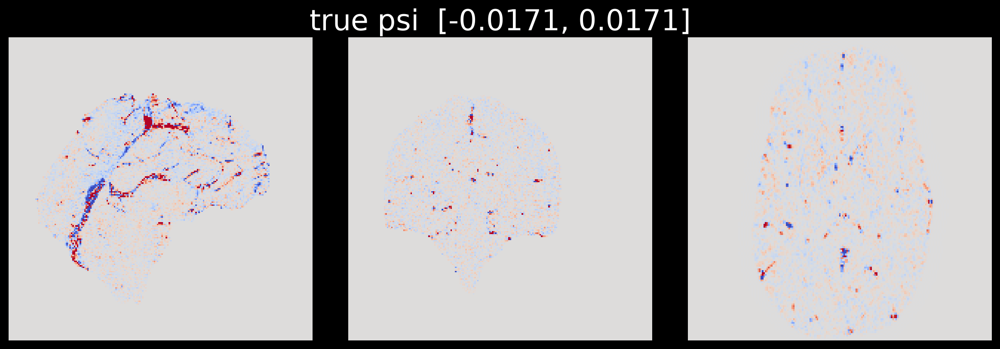

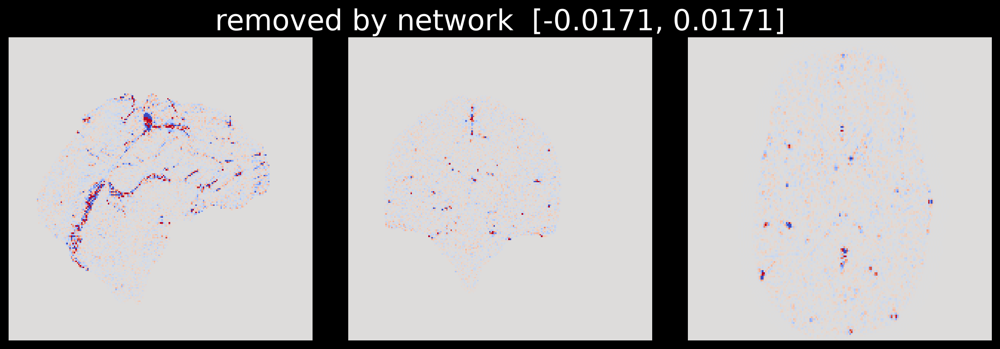

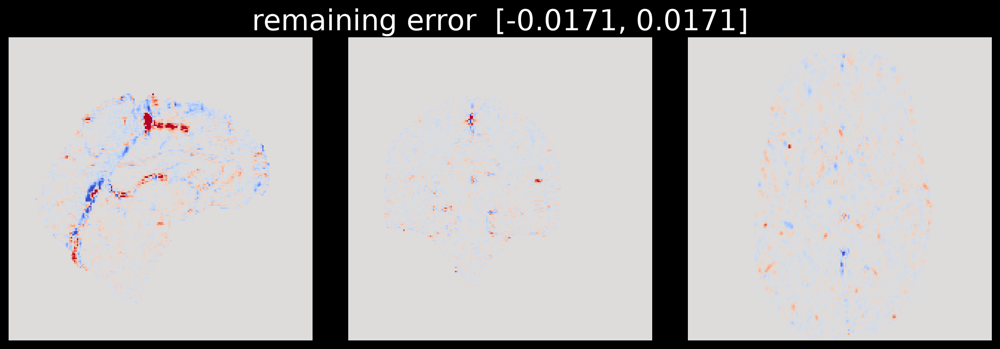

phase NRMSE: dirty 42.24% -> cleaned 26.26%


In [6]:
cl = field[MAIN]
removed = (field["dirty"] - cl) * mask
rem_err = (cl - clean) * mask
a = np.percentile(np.abs(psi[mask]), 99.5)
c99 = np.percentile(np.abs(clean[mask]), 99)
show([field["dirty"], cl, clean], ["dirty", f"cleaned ({MAIN})", "clean target"], -c99, c99)
show([psi, removed, rem_err], ["true psi", "removed by network", "remaining error"], -a, a, cmap="coolwarm")
print("phase NRMSE: dirty %.2f%% -> cleaned %.2f%%" % (nrmse(field["dirty"], clean), nrmse(cl, clean)))

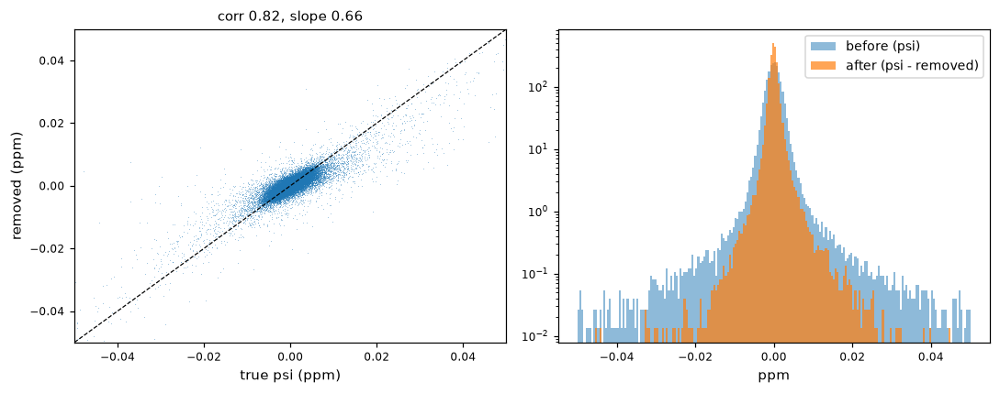

In [7]:
# does the removed component agree with the true psi? (subsample of in-mask voxels)
rng = np.random.default_rng(0)
sel = rng.choice(np.flatnonzero(mask.ravel()), 150000, replace=False)
x, y = psi.ravel()[sel], removed.ravel()[sel]
slope = (x * y).sum() / (x * x).sum()
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(x, y, ",", alpha=.4); ax[0].plot([-.05, .05], [-.05, .05], "k--", lw=.8)
ax[0].set_xlim(-.05, .05); ax[0].set_ylim(-.05, .05)
ax[0].set_xlabel("true psi (ppm)"); ax[0].set_ylabel("removed (ppm)"); ax[0].set_title(f"corr {np.corrcoef(x, y)[0, 1]:.2f}, slope {slope:.2f}")
ax[1].hist(x, bins=200, range=(-.05, .05), alpha=.5, label="before (psi)", density=True)
ax[1].hist(x - y, bins=200, range=(-.05, .05), alpha=.7, label="after (psi - removed)", density=True)
ax[1].set_yscale("log"); ax[1].legend(); ax[1].set_xlabel("ppm")
plt.tight_layout(); plt.show()

## 4. Which frequencies does each method fix?

The error field of a method is `field - clean`. Left: its radial power spectrum (lower is better; the dirty field's error is `psi`). Right: error power divided by the dirty field's error power in bands of `|D|` (the cone bands matter most for streaking) and of `|k|`.

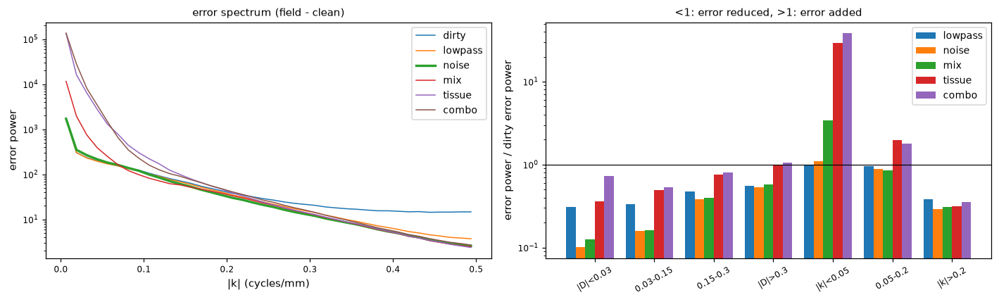

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for m in methods:
    if m == "oracle": continue
    k, s = radial_spectrum(field[m] - clean); ax[0].semilogy(k, s, label=m, lw=2.2 if m == MAIN else 1)
ax[0].set_xlabel("|k| (cycles/mm)"); ax[0].set_ylabel("error power"); ax[0].legend(); ax[0].set_title("error spectrum (field - clean)")
bands = [("|D|<0.03", np.abs(D) < 0.03), ("0.03-0.15", (np.abs(D) >= 0.03) & (np.abs(D) < 0.15)),
         ("0.15-0.3", (np.abs(D) >= 0.15) & (np.abs(D) < 0.3)), ("|D|>0.3", np.abs(D) >= 0.3),
         ("|k|<0.05", KR < 0.05), ("0.05-0.2", (KR >= 0.05) & (KR < 0.2)), ("|k|>0.2", KR >= 0.2)]
base = [band_power(psi, s) for _, s in bands]
shown = [m for m in methods if m not in ("dirty", "oracle")]
w = 0.8 / len(shown)
for i, m in enumerate(shown):
    r = [band_power(field[m] - clean, s) / b for (_, s), b in zip(bands, base)]
    ax[1].bar(np.arange(len(bands)) + i * w, r, w, label=m)
ax[1].axhline(1, color="k", lw=.8); ax[1].set_yscale("log")
ax[1].set_xticks(np.arange(len(bands)) + 0.4); ax[1].set_xticklabels([b for b, _ in bands], rotation=30)
ax[1].set_ylabel("error power / dirty error power"); ax[1].legend(); ax[1].set_title("<1: error reduced, >1: error added")
plt.tight_layout(); plt.show()

## 5. Cleaned fields of all methods (axial) and their errors

Top: the field fed to eNDI. Bottom: field minus clean. `tissue` and `combo` do not necessarily look bad here, which is why the inversion section matters.

In [ ]:
ms = [m for m in methods if m != "oracle"]
show([field[m] for m in ms], [f"{m}\n{meta[m]['phase_nrmse']:.1f}%" for m in ms], -c99, c99)
key = [m for m in ["dirty", "lowpass", MAIN, "mix", "tissue"] if m in field]
show([(field[m] - clean) * mask for m in key], [f"error {m}" for m in key], -a, a, cmap="coolwarm")

## 6. The inversion (eNDI, identical settings for every field)

Each field was passed through the same eNDI with automatic stopping. Top: susceptibility maps. Bottom: `chi_hat - chi_gt` inside the mask. The oracle (true clean field in the mask) is the practical reference, not a perfect ceiling.

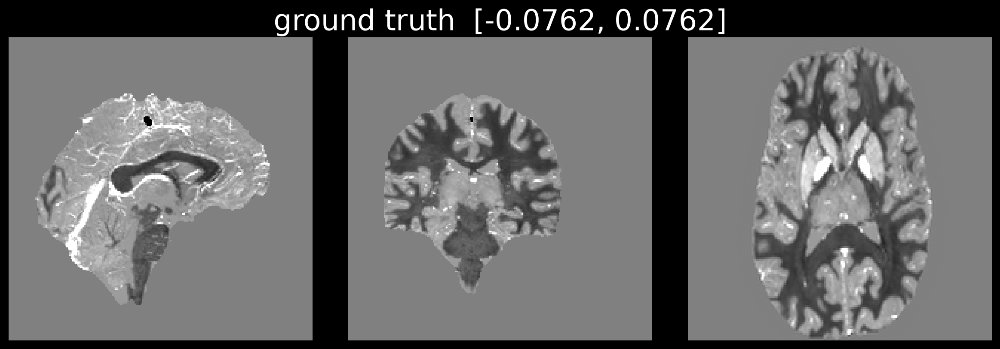

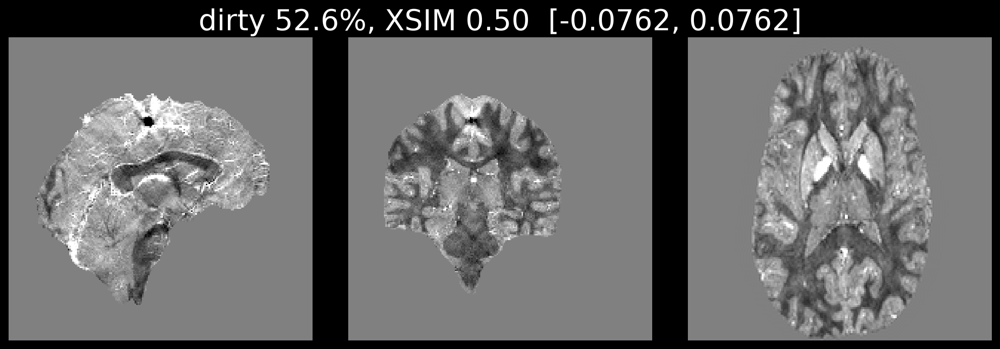

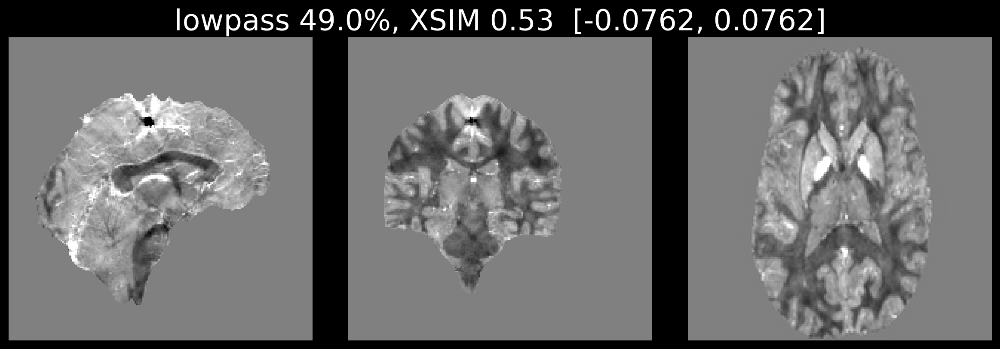

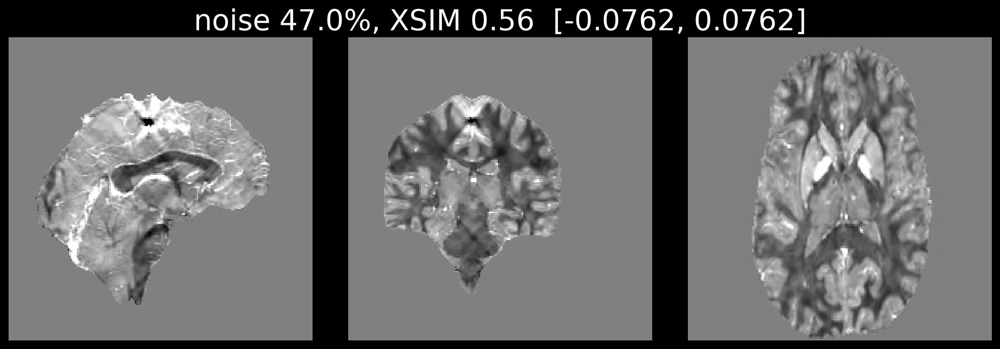

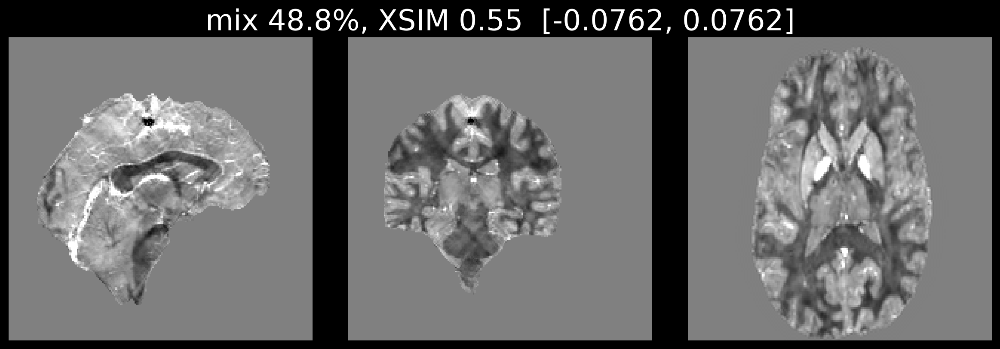

...

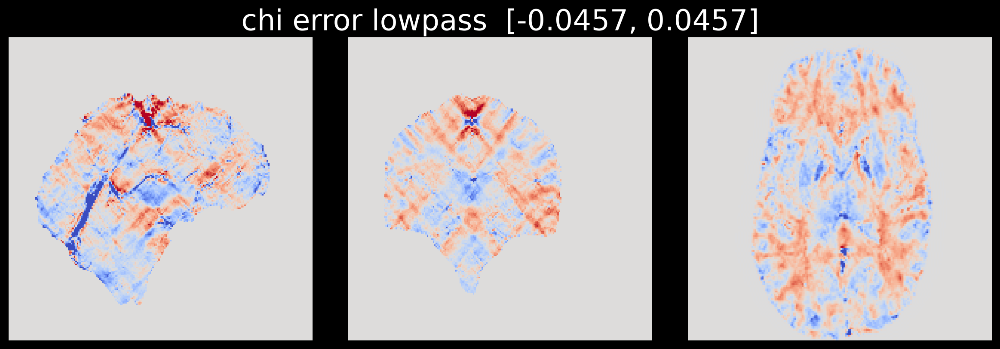

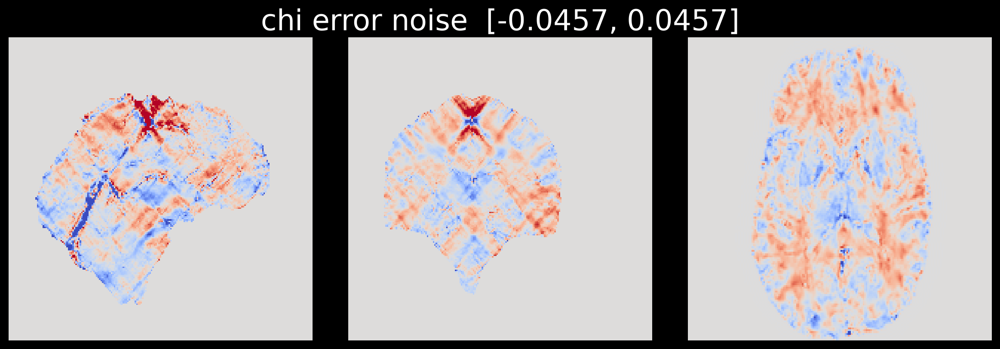

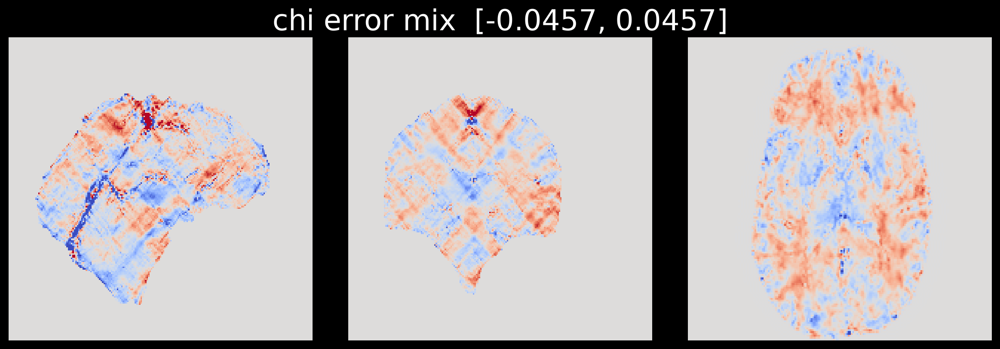

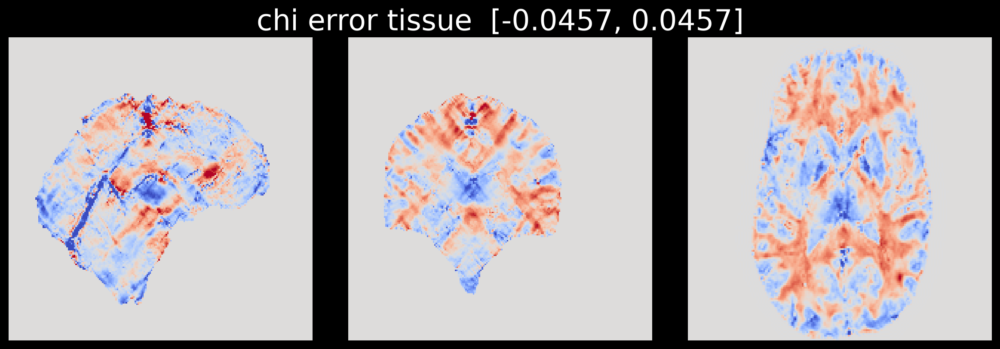

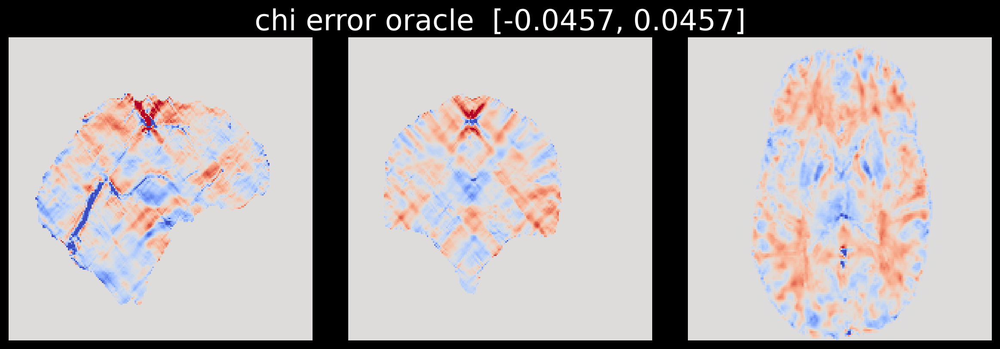

In [9]:
el = lim * 0.6
show([chi_gt * mask] + [chi_hat[m] * mask for m in methods],
     ["ground truth"] + [f"{m}\n{meta[m]['endi_nrmse']:.1f}%, XSIM {meta[m]['xsim']:.2f}" for m in methods],
     -lim, lim)
key = [m for m in ["dirty", "lowpass", MAIN, "mix", "tissue", "oracle"] if m in chi_hat]
show([(chi_hat[m] - chi_gt) * mask for m in key], [f"chi error {m}" for m in key], -el, el, cmap="coolwarm")

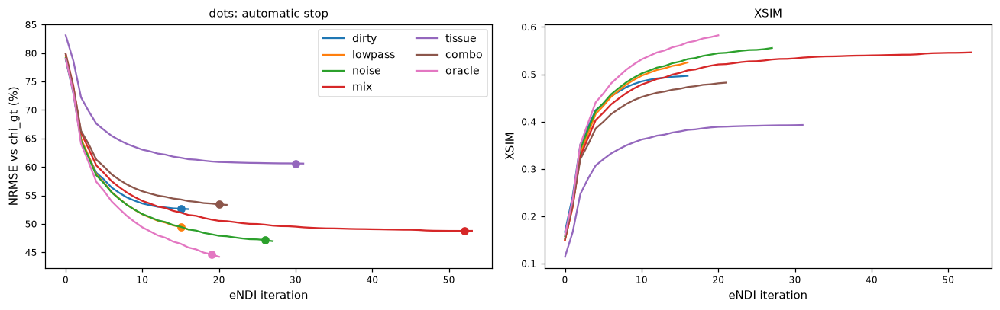

In [10]:
# convergence against the ground truth; dots mark where the automatic stop fired
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for m in methods:
    h = meta[m]
    l, = ax[0].plot(h["nrmse_history"], label=m)
    j = min(h["stop"] - 1, len(h["nrmse_history"]) - 1)
    ax[0].plot(j, h["nrmse_history"][j], "o", color=l.get_color())
    ax[1].plot(h["xsim_history"], color=l.get_color(), label=m)
ax[0].set_xlabel("eNDI iteration"); ax[0].set_ylabel("NRMSE vs chi_gt (%)"); ax[0].set_title("dots: automatic stop"); ax[0].legend(ncol=2)
ax[1].set_xlabel("eNDI iteration"); ax[1].set_ylabel("XSIM"); ax[1].set_title("XSIM")
plt.tight_layout(); plt.show()

## 7. Zoom: where is the gain?

An axial window (change `ROI` to look elsewhere). Streaking appears as stripes along the cone directions.

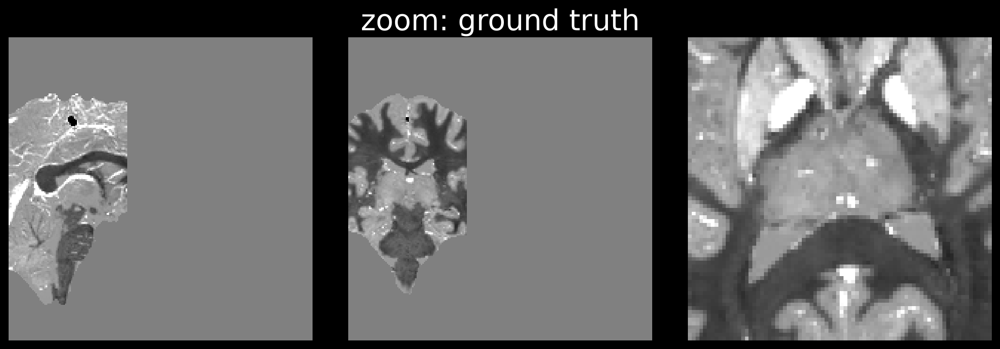

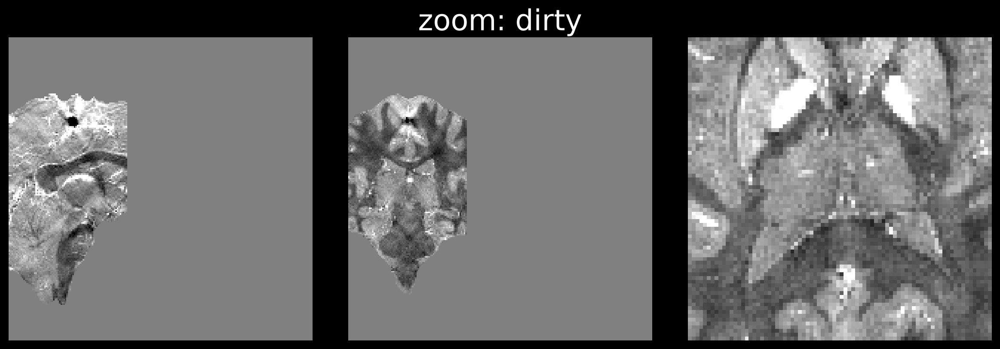

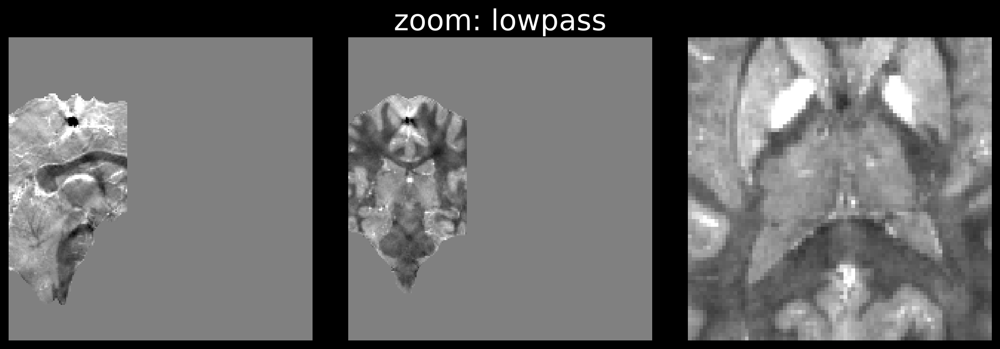

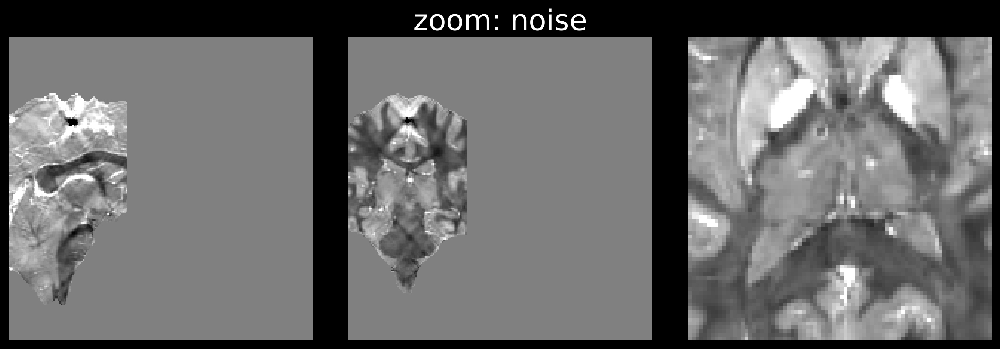

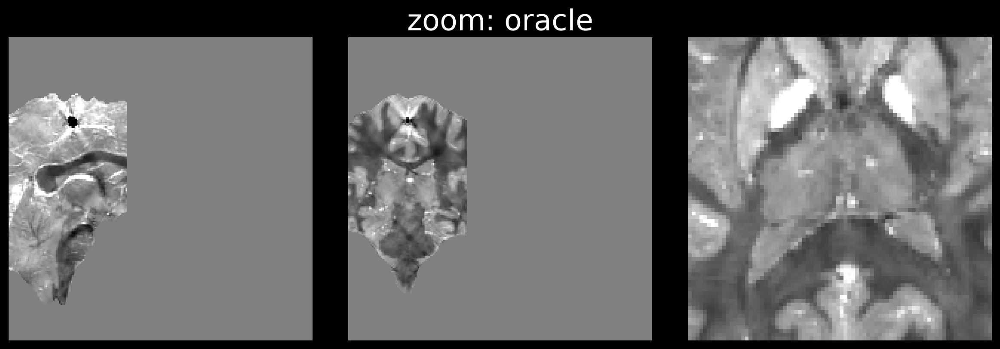

In [11]:
ROI = (slice(centre[0] - 40, centre[0] + 40), slice(centre[1] - 40, centre[1] + 40), slice(None))
zoom_pos = (40, 40, centre[2])
for t, v in [("ground truth", chi_gt * mask)] + [(m, chi_hat[m] * mask) for m in ["dirty", "lowpass", MAIN, "oracle"] if m in chi_hat]:
    imagesc3d2(v[ROI], zoom_pos, cmap="gray", contrast=[-lim, lim], fig_num=1, rot_deg=ROT, scale_fig=[-0.12, 0.12, -0.12, 0.12],
               title_fig=f"zoom: {t}")

In [12]:
# share of the chi error power that sits near the cone (|D| < 0.1)
print(f"{'method':10s} {'chi err rms (ppm)':>18s} {'error power in |D|<0.1':>24s}")
for m in methods:
    err = (chi_hat[m] - chi_gt) * mask
    print(f"{m:10s} {rms(err):18.4f} {100 * energy_fraction(err, np.abs(D) < 0.1):23.1f}%")

method      chi err rms (ppm)   error power in |D|<0.1
dirty                  0.0153                    39.4%
lowpass                0.0142                    44.0%
noise                  0.0136                    45.5%
mix                    0.0142                    42.8%
tissue                 0.0176                    35.9%
combo                  0.0155                    38.0%
oracle                 0.0128                    50.3%


## 8. Phase error is not enough

Phase NRMSE (distance of the cleaned field to `D*chi`) against the final eNDI NRMSE. If phase error predicted the inversion, the points would follow a line. `tissue` has a *lower* phase error than the dirty field but a much *worse* inversion: it changes dipole-compatible content, which eNDI then explains as susceptibility.

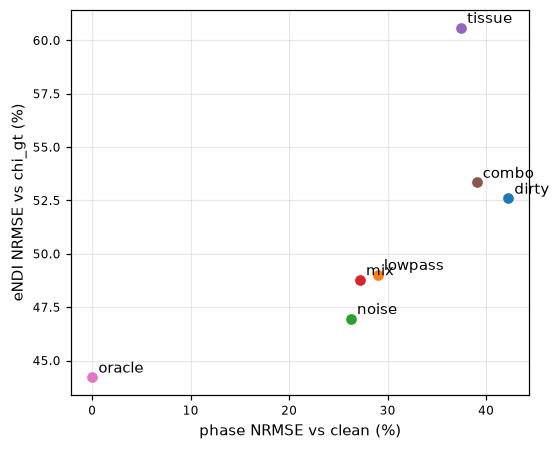

In [13]:
fig, ax = plt.subplots(figsize=(5.2, 4.2))
for m in methods:
    ax.plot(meta[m]["phase_nrmse"], meta[m]["endi_nrmse"], "o")
    ax.annotate(m, (meta[m]["phase_nrmse"], meta[m]["endi_nrmse"]), xytext=(4, 3), textcoords="offset points")
ax.set_xlabel("phase NRMSE vs clean (%)"); ax.set_ylabel("eNDI NRMSE vs chi_gt (%)"); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

|D|<0.03   true psi 5.352e+06   removed(tissue) 7.129e+06   removed(noise) 4.681e+06
0.03-0.15  true psi 2.223e+07   removed(tissue) 2.885e+07   removed(noise) 1.792e+07
0.15-0.3   true psi 3.797e+07   removed(tissue) 3.710e+07   removed(noise) 2.083e+07
|D|>0.3    true psi 4.623e+07   removed(tissue) 4.462e+07   removed(noise) 1.683e+07


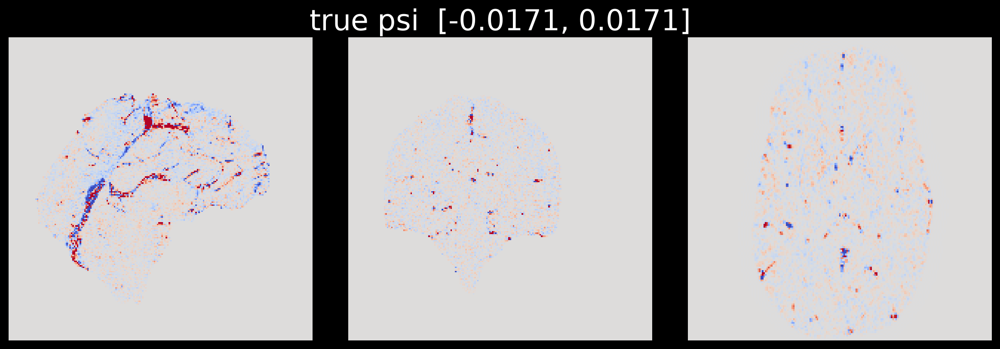

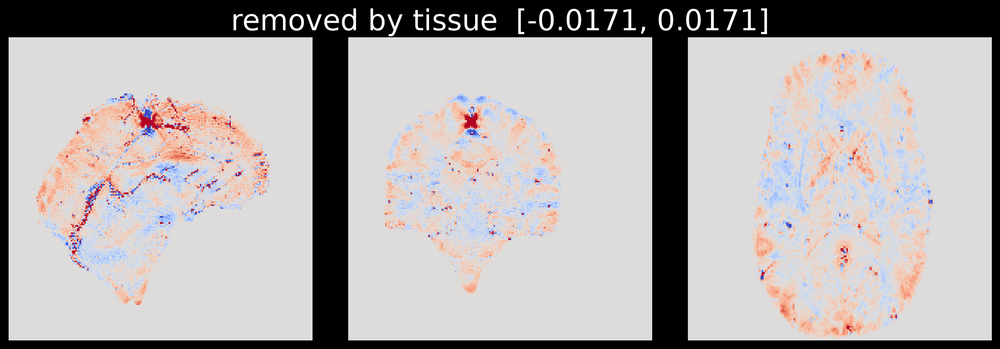

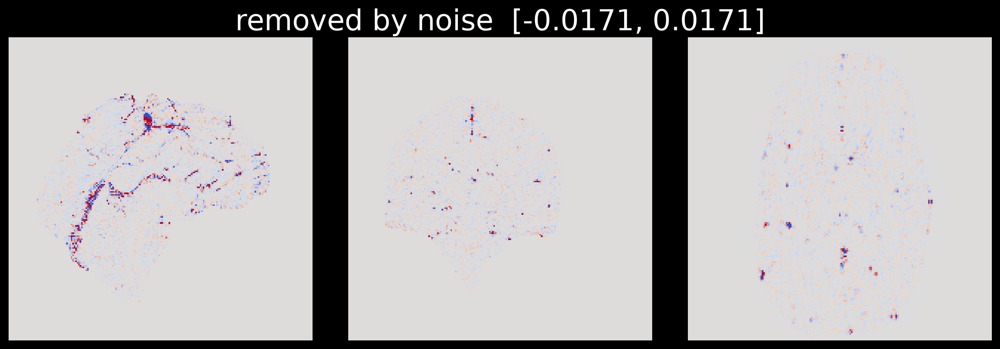

In [14]:
# tissue: what did it remove, compared with the true psi and with the main run? (power per |D| band)
if "tissue" in field:
    removed_t = (field["dirty"] - field["tissue"]) * mask
    removed_m = (field["dirty"] - field[MAIN]) * mask
    for name, sel_ in bands[:4]:
        print(f"{name:10s} true psi {band_power(psi, sel_):.3e}   removed(tissue) {band_power(removed_t, sel_):.3e}   removed({MAIN}) {band_power(removed_m, sel_):.3e}")
    show([psi, removed_t, removed_m], ["true psi", "removed by tissue", f"removed by {MAIN}"], -a, a, cmap="coolwarm")

## Reading guide and caveats

* One volume (Sim2), one training head (RC1). `noise` is a **single seed**; the mixture has three seeds (49.05 +- 0.19 % eNDI).
* The low-pass sigma was tuned on this very volume; the noise SNR range was chosen knowing Sim2's `psi` level.
* What to look for: less error power in the cone bands (Section 4) is what turns into less streaking after inversion (Sections 6-7).

In [17]:
field["dirty"].shape

(164, 205, 205)

In [20]:
from FANSI_tools import dipole_kernel

In [13]:
spatialRes2 = np.array([1,1,1])
N2 = field["dirty"].shape
FOV2 = np.array(N2) * np.array(spatialRes2)
kernel2 =  np.fft.ifftshift(dipole_kernel(N2, FOV2))

In [18]:
clean_full = np.real(np.fft.ifftn(kernel2 * np.fft.fftn(chi_gt)))

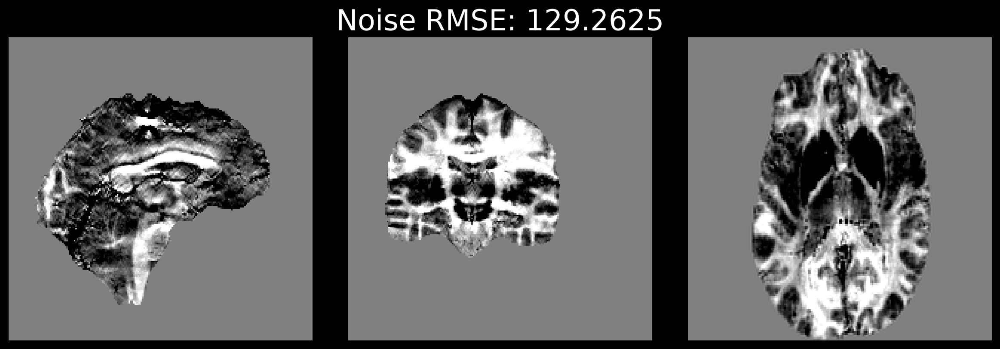

In [15]:
input_phase = field["dirty"]
threshold_tkd = 0.1

kernel_inv = np.zeros_like(kernel2, dtype=np.complex64)

mask_safe = np.abs(kernel2) >= threshold_tkd
mask_unsafe = ~mask_safe  # The rest

# Safe inversion
kernel_inv[mask_safe] = 1.0 / kernel2[mask_safe]

# Truncated inversion with sign
kernel_inv[mask_unsafe] = np.sign(kernel2[mask_unsafe]) / threshold_tkd
# Apply the inverse filter in Fourier domain
chi_tkd1 = np.real(np.fft.ifftn(np.fft.fftn(input_phase) * kernel_inv))
imagesc3d2((chi_tkd1)* mask ,  tuple(x // 2 for x in N2),cmap='grey', fig_num=2, rot_deg=[90,90,90], avg_size=0, title_fig=f"Noise RMSE: {compute_rmse(mask* (chi_gt), mask* chi_tkd1):.4f}")

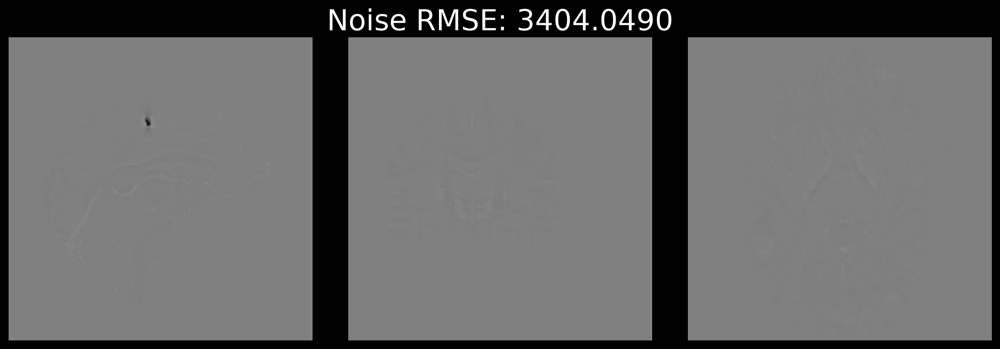

In [25]:
input_phase = clean_full/phs_scale
threshold_tkd = 0.1

kernel_inv = np.zeros_like(kernel2, dtype=np.complex64)

mask_safe = np.abs(kernel2) >= threshold_tkd
mask_unsafe = ~mask_safe  # The rest

# Safe inversion
kernel_inv[mask_safe] = 1.0 / kernel2[mask_safe]

# Truncated inversion with sign
kernel_inv[mask_unsafe] = np.sign(kernel2[mask_unsafe]) / threshold_tkd
# Apply the inverse filter in Fourier domain
chi_tkd1 = np.real(np.fft.ifftn(np.fft.fftn(input_phase) * kernel_inv))
imagesc3d2((chi_tkd1)* mask ,  tuple(x // 2 for x in N2),cmap='grey', fig_num=2, rot_deg=[90,90,90], avg_size=0, title_fig=f"Noise RMSE: {compute_rmse(mask* (chi_gt), mask* chi_tkd1):.4f}")

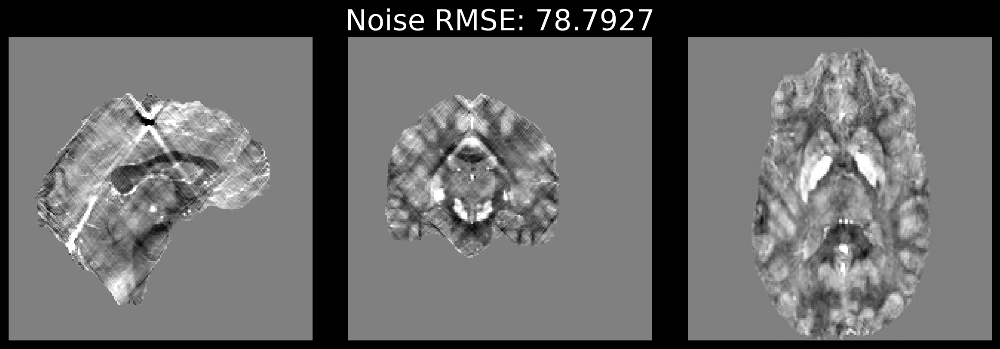

In [30]:
input_phase = cl
threshold_tkd = 0.01

kernel_inv = np.zeros_like(kernel2, dtype=np.complex64)

mask_safe = np.abs(kernel2) >= threshold_tkd
mask_unsafe = ~mask_safe  # The rest

# Safe inversion
kernel_inv[mask_safe] = 1.0 / kernel2[mask_safe]

# Truncated inversion with sign
kernel_inv[mask_unsafe] = np.sign(kernel2[mask_unsafe]) / threshold_tkd
# Apply the inverse filter in Fourier domain
chi_tkd1 = np.real(np.fft.ifftn(np.fft.fftn(input_phase) * kernel_inv))
imagesc3d2((chi_tkd1)* mask ,  tuple(x // 2 for x in N2),cmap='grey', fig_num=2, rot_deg=[90,90,90], avg_size=0, title_fig=f"Noise RMSE: {compute_rmse(mask* (chi_gt), mask* chi_tkd1):.4f}")

 threshold  RMSE unmasked input  RMSE masked input
       0.1               18.28%             38.15%
      0.03                7.65%             50.04%
      0.01                3.77%             69.29%
     0.001                1.15%            252.81%
    0.0001                0.68%            758.14%
     1e-06                0.65%          59540.27%


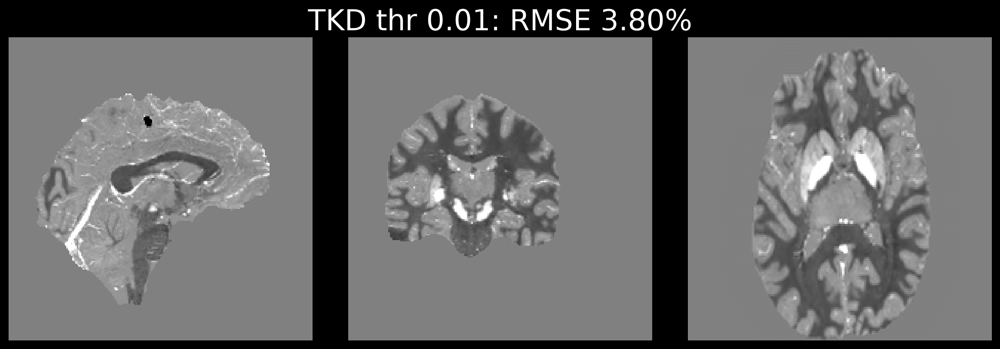

In [30]:

spatialRes2 = np.array([1, 1, 1])
N2 = field["dirty"].shape

def dipole_kernel_aligned(N, res):
    """Dipole kernel, B0 || z, native FFT order (DC at index 0), correct for odd N too."""
    kx, ky, kz = np.meshgrid(*[np.fft.fftfreq(n, d=r) for n, r in zip(N, res)], indexing="ij")
    k2 = kx**2 + ky**2 + kz**2
    kernel = 1 / 3 - kz**2 / np.where(k2 == 0, 1, k2)
    kernel[0, 0, 0] = 0
    return kernel

def tkd_inverse(field_in, kernel, threshold):
    inv = np.where(np.abs(kernel) >= threshold, 1 / np.where(kernel == 0, 1, kernel), np.sign(kernel) / threshold)
    return np.real(np.fft.ifftn(np.fft.fftn(field_in) * inv))

kernel2 = dipole_kernel_aligned(N2, spatialRes2)

# clean field of the ground truth: whole volume, NOT multiplied by the mask
clean_full = np.real(np.fft.ifftn(kernel2 * np.fft.fftn(chi_gt)))

print(f"{'threshold':>10s} {'RMSE unmasked input':>20s} {'RMSE masked input':>18s}")
for thr in [0.1, 0.03, 0.01, 1e-3, 1e-4, 1e-6]:
    chi_a = tkd_inverse(clean_full, kernel2, thr)            # tends to the ground truth
    chi_b = tkd_inverse(clean_full * mask, kernel2, thr)     # your previous input: gets worse as thr -> 0
    print(f"{thr:10g} {compute_rmse(mask * chi_a, mask * chi_gt):19.2f}% {compute_rmse(mask * chi_b, mask * chi_gt):17.2f}%")

threshold_tkd = 0.01
chi_tkd1 = tkd_inverse(clean_full, kernel2, threshold_tkd)
imagesc3d2(chi_tkd1 * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"TKD thr {threshold_tkd}: RMSE {compute_rmse(mask * chi_gt, mask * chi_tkd1):.2f}%")

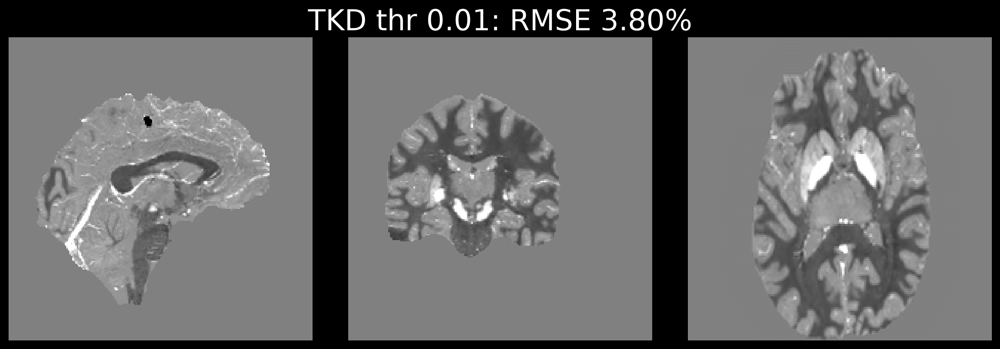

In [43]:
threshold_tkd = 0.01
chi_tkd1 = tkd_inverse(clean_full, kernel2, threshold_tkd)
imagesc3d2(chi_tkd1 * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"TKD thr {threshold_tkd}: RMSE {compute_rmse(mask * chi_gt, mask * chi_tkd1):.2f}%")

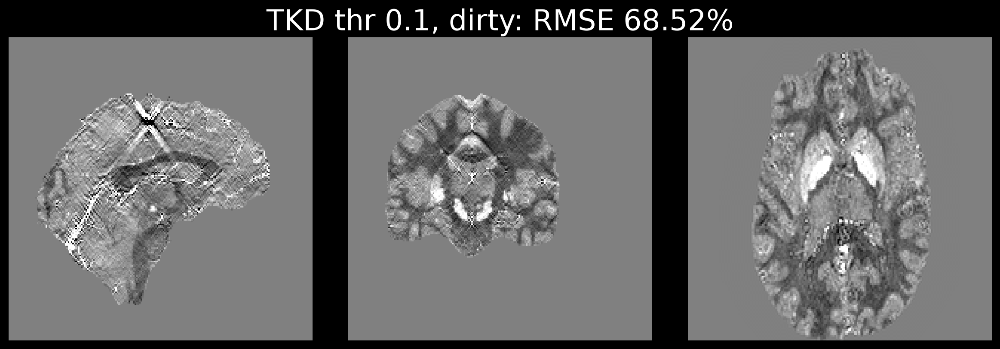

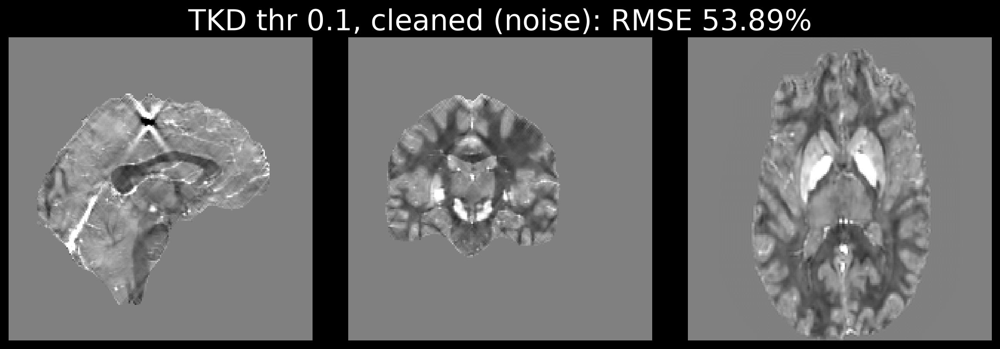

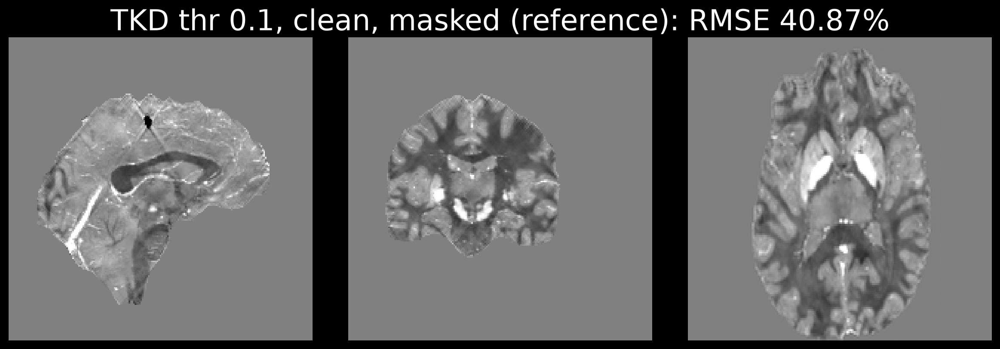

In [31]:

threshold_tkd = 0.1      # with a masked input a small threshold blows up; 0.1-0.2 is the usual TKD range

to_invert = {
    "dirty": field["dirty"],
    f"cleaned ({MAIN})": field[MAIN],
    "clean, masked (reference)": field["oracle"],     # mask * D*chi
}
for name, f_in in to_invert.items():
    chi_tkd = tkd_inverse(f_in, kernel2, threshold_tkd)
    imagesc3d2(chi_tkd * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
               title_fig=f"TKD thr {threshold_tkd}, {name}: RMSE {compute_rmse(mask * chi_gt, mask * chi_tkd):.2f}%")

In [7]:
import torch, eNDI_module_torch
from FANSI_tools import dipole_kernel

In [8]:

TE, B0 = 8e-3, 7.0
phs_scale = TE * 2 * np.pi * 42.58 * B0          # ppm -> radians
PAD = 256
kernel_pad = dipole_kernel((PAD,) * 3, (PAD,) * 3)   # 1 mm, cornered, as in the paper notebook

In [9]:

def pad_corner(v):
    out = np.zeros((PAD,) * 3, dtype=np.float64)
    out[tuple(slice(0, n) for n in v.shape)] = v
    return out

mask_padded = pad_corner(mask.astype(np.float64))
weight_padded = pad_corner(weight)
chi_padded = pad_corner(chi_gt)

In [10]:

def run_endi(field_ppm):
    params = {"K": kernel_pad, "input": pad_corner(field_ppm) * phs_scale, "alpha": 1e-5, "isNonlinear": True,
              "weight": weight_padded, "mask": mask_padded, "maxOuterIter": 50, "tolUpdate": 1e-10,
              "chi_cosmos": chi_padded * phs_scale, "isXSIM": True, "scale": 1.0}
    out = eNDI_module_torch.ndiCG_auto(params)
    torch.cuda.empty_cache()
    chi_hat = (out["x"] / phs_scale)[tuple(slice(0, n) for n in N2)]
    return chi_hat, out

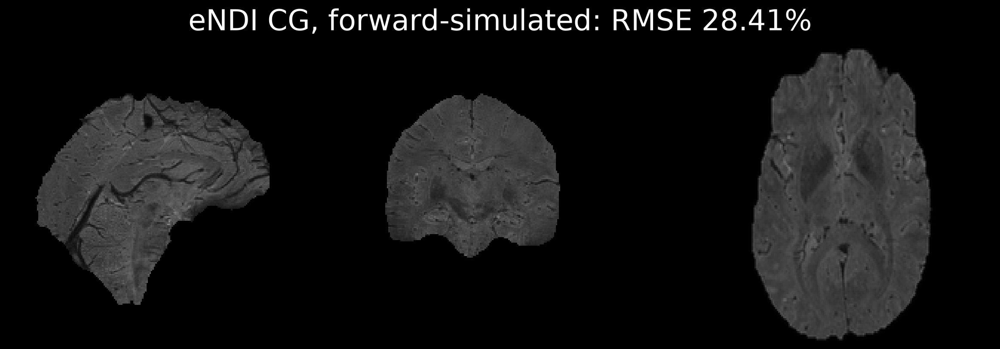

In [60]:

imagesc3d2(weight * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[0, 1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"eNDI CG, forward-simulated: RMSE {compute_rmse(mask * chi_fwd, mask * chi_gt):.2f}%")

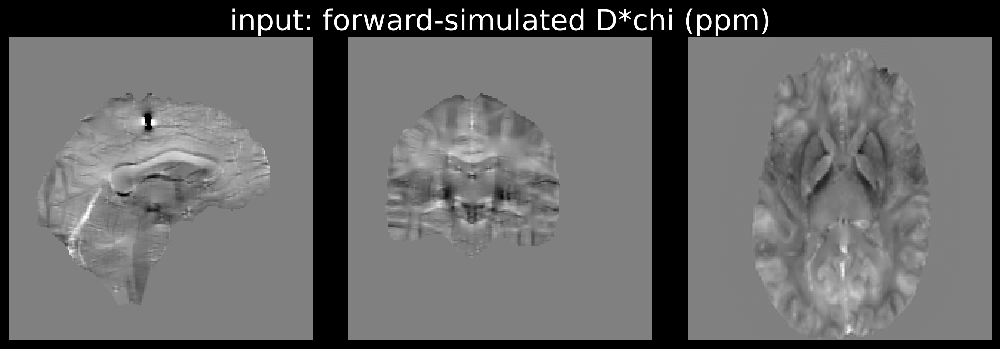

Iter: 0   Update: 100.000000   NRMSE: 78.1191%   XSIM: 0.1656
Iter: 1   Update: 24.501610   NRMSE: 72.1567%   XSIM: 0.2387
Iter: 2   Update: 33.458897   NRMSE: 63.0991%   XSIM: 0.3564
Iter: 3   Update: 14.734373   NRMSE: 59.1926%   XSIM: 0.4096
Iter: 4   Update: 14.028431   NRMSE: 55.5537%   XSIM: 0.4567
Iter: 5   Update: 6.642258   NRMSE: 53.7227%   XSIM: 0.4784
Iter: 6   Update: 7.225011   NRMSE: 51.8580%   XSIM: 0.4999
Iter: 7   Update: 4.545571   NRMSE: 50.5010%   XSIM: 0.5152
Iter: 8   Update: 4.937904   NRMSE: 49.1083%   XSIM: 0.5310
Iter: 9   Update: 3.247857   NRMSE: 48.0509%   XSIM: 0.5427
Iter: 10   Update: 3.822709   NRMSE: 46.9271%   XSIM: 0.5549
Iter: 11   Update: 2.122345   NRMSE: 46.2236%   XSIM: 0.5623
Iter: 12   Update: 3.150601   NRMSE: 45.2662%   XSIM: 0.5721
Iter: 13   Update: 1.533996   NRMSE: 44.7483%   XSIM: 0.5773
Iter: 14   Update: 2.887496   NRMSE: 43.8311%   XSIM: 0.5864
Iter: 15   Update: 1.636827   NRMSE: 43.2699%   XSIM: 0.5919
Iter: 16   Update: 2.470950 

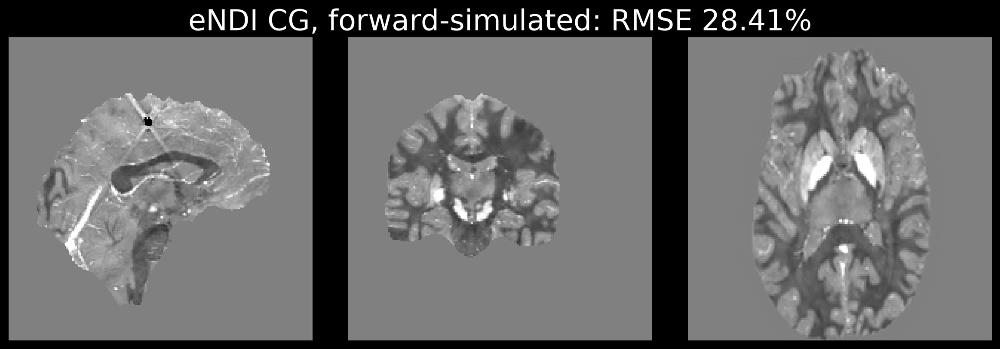

In [55]:


input_fwd = clean_full
imagesc3d2(input_fwd * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: forward-simulated D*chi (ppm)")

chi_fwd, out_fwd = run_endi(input_fwd)
print("stop iteration", out_fwd["iter"], "XSIM", out_fwd["xsim_history"][-1])

imagesc3d2(chi_fwd * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"eNDI CG, forward-simulated: RMSE {compute_rmse(mask * chi_fwd, mask * chi_gt):.2f}%")

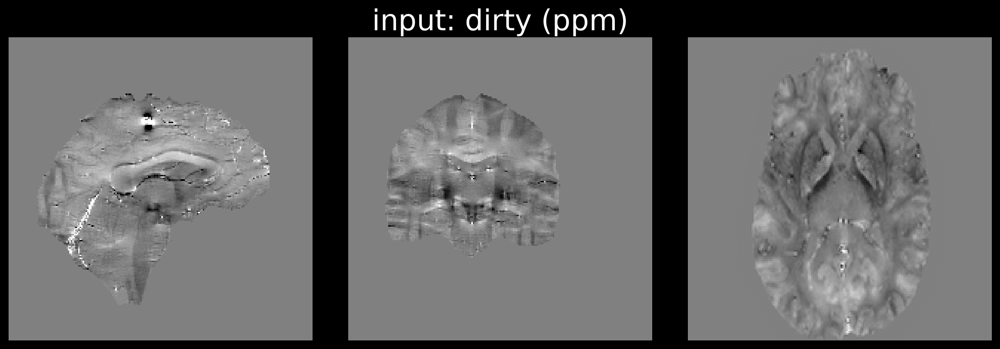

Iter: 0   Update: 100.000000   NRMSE: 78.8901%   XSIM: 0.1671
Iter: 1   Update: 26.807285   NRMSE: 72.9528%   XSIM: 0.2426
Iter: 2   Update: 34.672210   NRMSE: 64.5466%   XSIM: 0.3517
Iter: 3   Update: 13.557154   NRMSE: 61.7988%   XSIM: 0.3888
Iter: 4   Update: 14.817981   NRMSE: 58.9818%   XSIM: 0.4243
Iter: 5   Update: 6.784958   NRMSE: 57.7853%   XSIM: 0.4379
Iter: 6   Update: 8.015115   NRMSE: 56.3743%   XSIM: 0.4535
Iter: 7   Update: 5.442286   NRMSE: 55.4494%   XSIM: 0.4635
Iter: 8   Update: 5.597181   NRMSE: 54.6444%   XSIM: 0.4729
Iter: 9   Update: 4.240727   NRMSE: 54.0747%   XSIM: 0.4797
Iter: 10   Update: 4.211055   NRMSE: 53.5856%   XSIM: 0.4851
Iter: 11   Update: 2.935637   NRMSE: 53.2809%   XSIM: 0.4885
Iter: 12   Update: 3.259265   NRMSE: 53.0205%   XSIM: 0.4914
Iter: 13   Update: 1.964413   NRMSE: 52.8897%   XSIM: 0.4930
Iter: 14   Update: 2.933037   NRMSE: 52.7327%   XSIM: 0.4949
Iter: 15   Update: 1.565580   NRMSE: 52.6739%   XSIM: 0.4957
Iter: 16   Update: 3.031726 

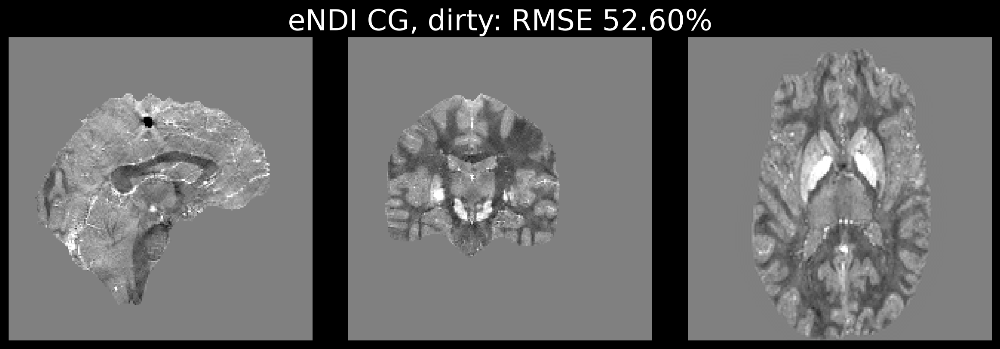

In [56]:

input_dirty = field["dirty"]
imagesc3d2(input_dirty, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: dirty (ppm)")

chi_dirty, out_dirty = run_endi(input_dirty)
print("stop iteration", out_dirty["iter"], "XSIM", out_dirty["xsim_history"][-1])

imagesc3d2(chi_dirty * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"eNDI CG, dirty: RMSE {compute_rmse(mask * chi_dirty, mask * chi_gt):.2f}%")

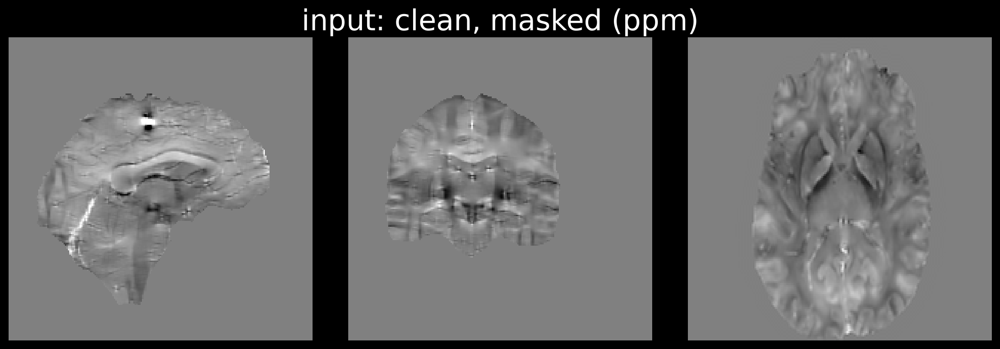

Iter: 0   Update: 100.000000   NRMSE: 79.1383%   XSIM: 0.1578
Iter: 1   Update: 26.072508   NRMSE: 73.2373%   XSIM: 0.2311
Iter: 2   Update: 34.491350   NRMSE: 64.6410%   XSIM: 0.3421
Iter: 3   Update: 13.460382   NRMSE: 61.6135%   XSIM: 0.3829
Iter: 4   Update: 14.461607   NRMSE: 58.5342%   XSIM: 0.4225
Iter: 5   Update: 6.546883   NRMSE: 57.1237%   XSIM: 0.4391
Iter: 6   Update: 7.491350   NRMSE: 55.5232%   XSIM: 0.4576
Iter: 7   Update: 5.027440   NRMSE: 54.3723%   XSIM: 0.4707
Iter: 8   Update: 5.060769   NRMSE: 53.3290%   XSIM: 0.4831
Iter: 9   Update: 3.811092   NRMSE: 52.4846%   XSIM: 0.4932
Iter: 10   Update: 3.765301   NRMSE: 51.7235%   XSIM: 0.5019
Iter: 11   Update: 2.465043   NRMSE: 51.1918%   XSIM: 0.5080
Iter: 12   Update: 2.961526   NRMSE: 50.6318%   XSIM: 0.5142
Iter: 13   Update: 1.526593   NRMSE: 50.3253%   XSIM: 0.5177
Iter: 14   Update: 2.830988   NRMSE: 49.8009%   XSIM: 0.5236
Iter: 15   Update: 1.567216   NRMSE: 49.5006%   XSIM: 0.5270
Iter: 16   Update: 2.747042 

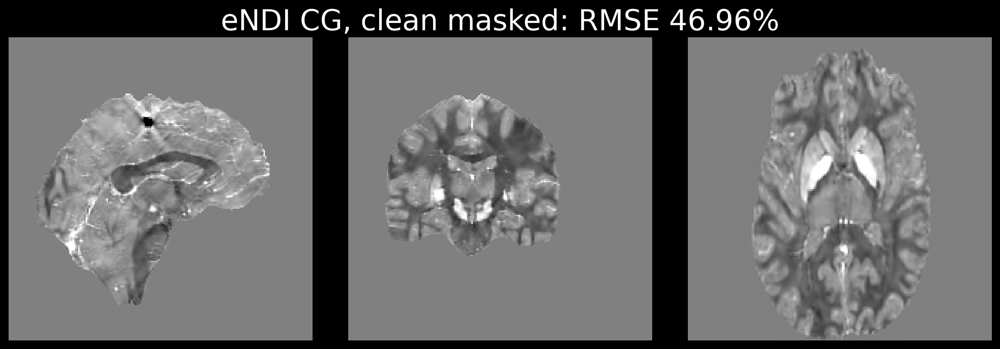

In [58]:

input_clean = field["noise"]          # = mask * D*chi
imagesc3d2(input_clean, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: clean, masked (ppm)")

chi_clean, out_clean = run_endi(input_clean)
print("stop iteration", out_clean["iter"], "XSIM", out_clean["xsim_history"][-1])

imagesc3d2(chi_clean * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"eNDI CG, clean masked: RMSE {compute_rmse(mask * chi_clean, mask * chi_gt):.2f}%")

In [37]:
imagesc3d2(chi_clean * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"eNDI CG, clean masked: RMSE {compute_rmse(mask * chi_clean, mask * chi_gt):.2f}%")

NameError: name 'chi_clean' is not defined

In [36]:
pad_ex = np.real(np.fft.ifftn(kernel2 * np.fft.fftn(chi_clean)))

NameError: name 'chi_clean' is not defined

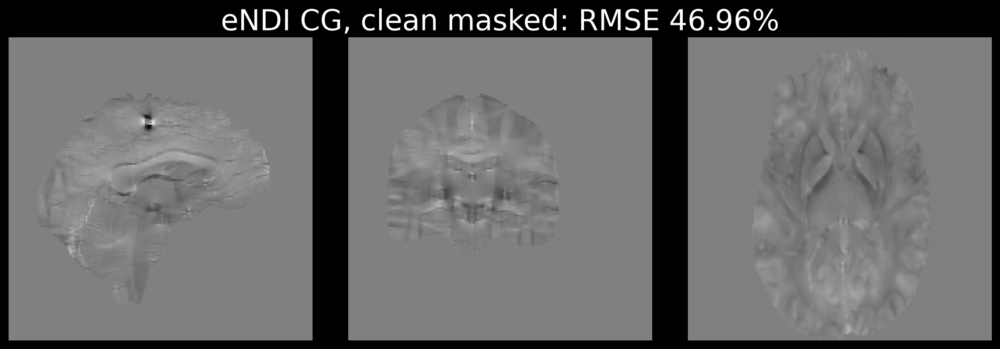

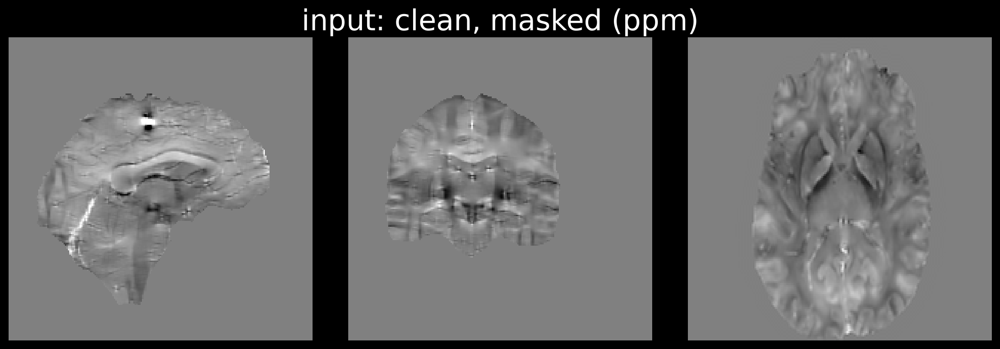

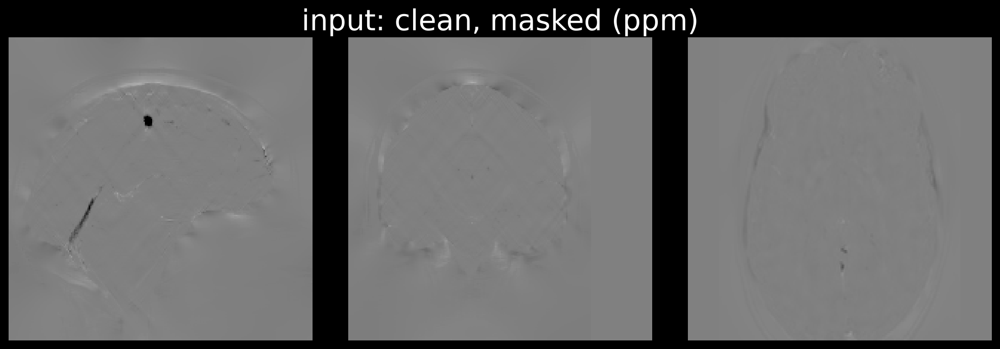

In [66]:
imagesc3d2(pad_ex * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"eNDI CG, clean masked: RMSE {compute_rmse(mask * chi_clean, mask * chi_gt):.2f}%")
imagesc3d2(input_clean, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: clean, masked (ppm)")
imagesc3d2(pad_ex - input_clean, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: clean, masked (ppm)")

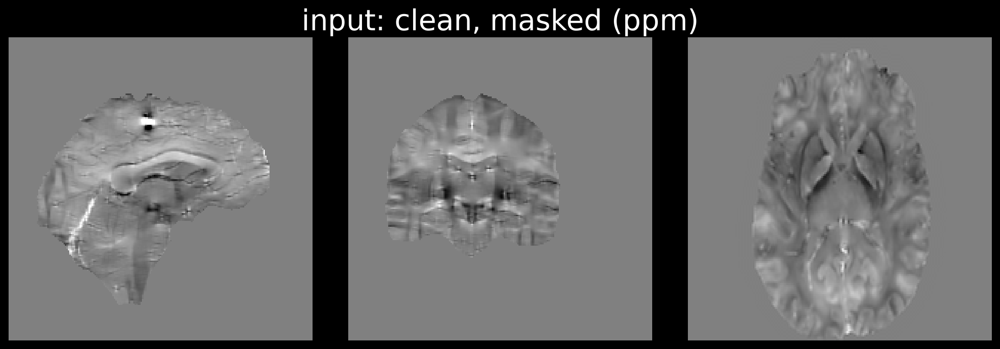

In [65]:
imagesc3d2(input_clean, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: clean, masked (ppm)")

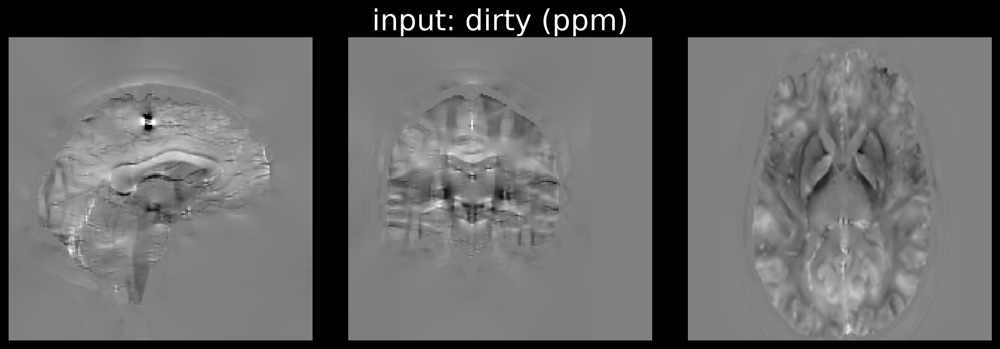

Iter: 0   Update: 100.000000   NRMSE: 79.2873%   XSIM: 0.1559
Iter: 1   Update: 26.183503   NRMSE: 73.4319%   XSIM: 0.2284
Iter: 2   Update: 34.067562   NRMSE: 65.0222%   XSIM: 0.3367
Iter: 3   Update: 13.978529   NRMSE: 61.9380%   XSIM: 0.3785
Iter: 4   Update: 13.953524   NRMSE: 59.0679%   XSIM: 0.4157
Iter: 5   Update: 6.955995   NRMSE: 57.6315%   XSIM: 0.4326
Iter: 6   Update: 6.972064   NRMSE: 56.2184%   XSIM: 0.4489
Iter: 7   Update: 5.041796   NRMSE: 55.1345%   XSIM: 0.4613
Iter: 8   Update: 4.679515   NRMSE: 54.2351%   XSIM: 0.4719
Iter: 9   Update: 3.628783   NRMSE: 53.4845%   XSIM: 0.4809
Iter: 10   Update: 3.481536   NRMSE: 52.8249%   XSIM: 0.4884
Iter: 11   Update: 2.168727   NRMSE: 52.3884%   XSIM: 0.4933
Iter: 12   Update: 2.759617   NRMSE: 51.8996%   XSIM: 0.4987
Iter: 13   Update: 1.251607   NRMSE: 51.6630%   XSIM: 0.5013
Iter: 14   Update: 2.751720   NRMSE: 51.1687%   XSIM: 0.5068
Iter: 15   Update: 1.550749   NRMSE: 50.8837%   XSIM: 0.5099
Iter: 16   Update: 2.359192 

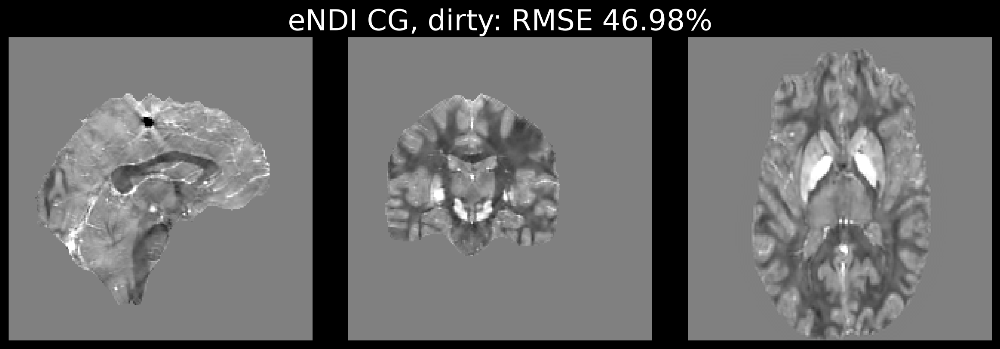

In [67]:

input_dirty = pad_ex
imagesc3d2(input_dirty, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: dirty (ppm)")

chi_dirty, out_dirty = run_endi(input_dirty)
print("stop iteration", out_dirty["iter"], "XSIM", out_dirty["xsim_history"][-1])

imagesc3d2(chi_dirty * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"eNDI CG, dirty: RMSE {compute_rmse(mask * chi_dirty, mask * chi_gt):.2f}%")

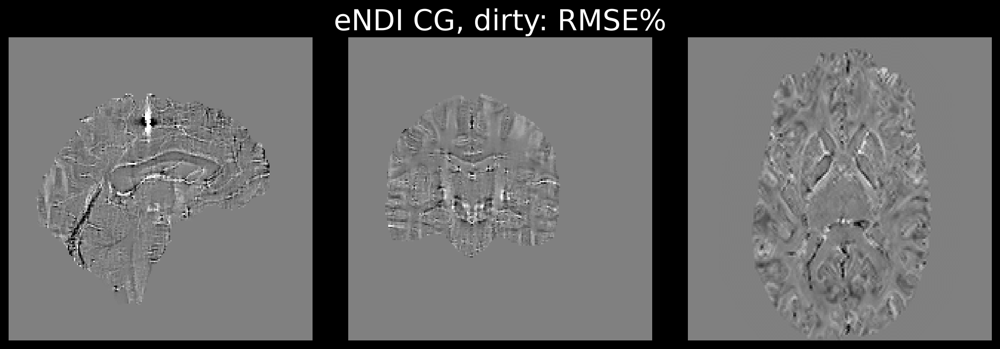

In [ ]:

imagesc3d2(clean_full * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.1, 0.1], fig_num=2, rot_deg=[90, 90, 90], avg_size=0,
           title_fig=f"eNDI CG, dirty: RMSE%")

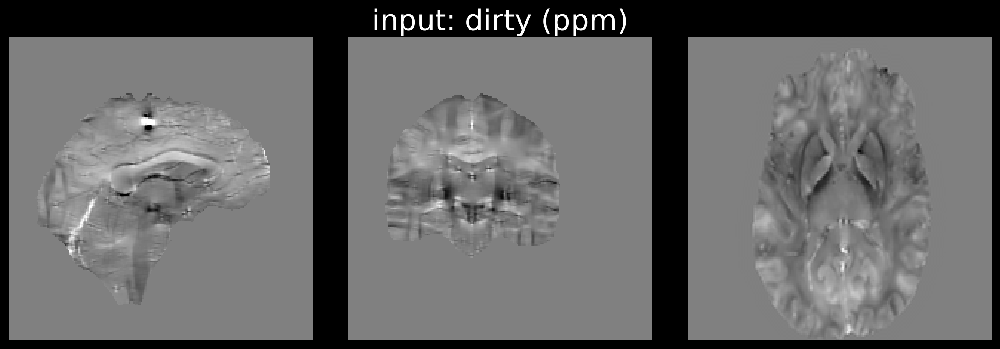

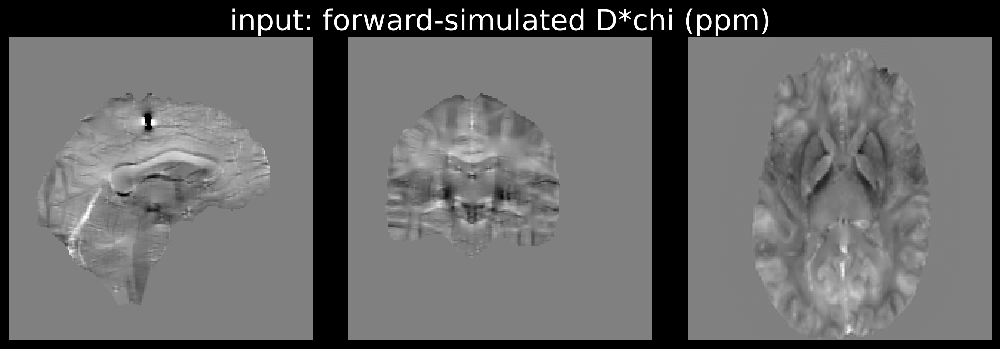

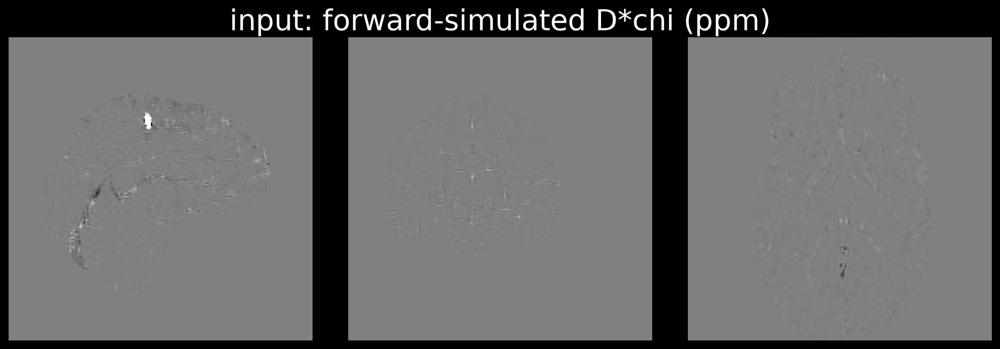

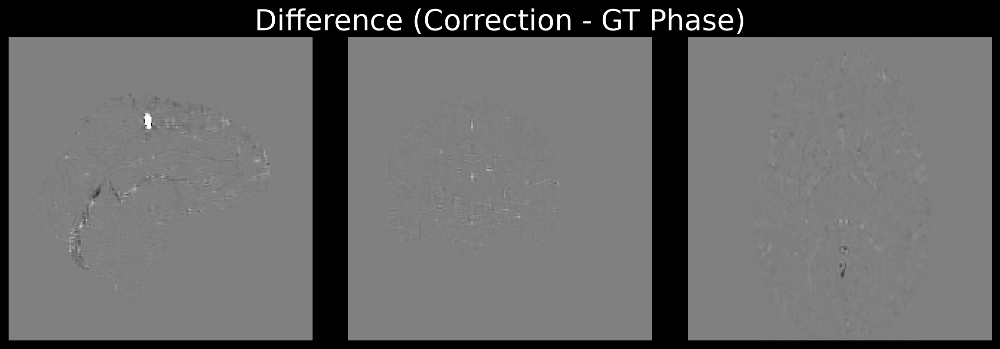

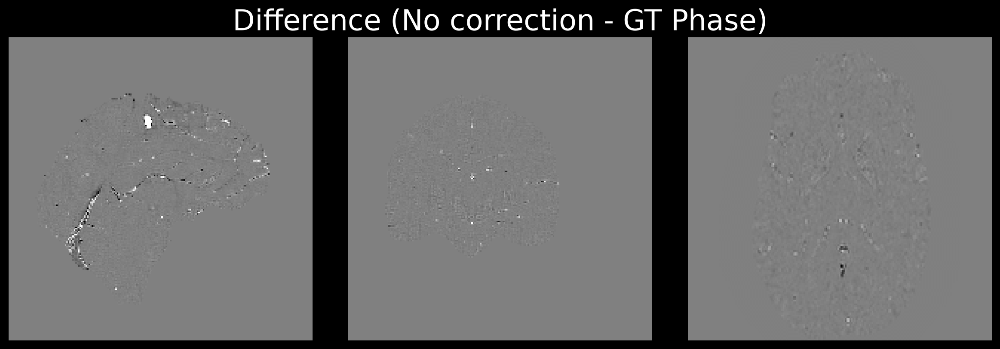

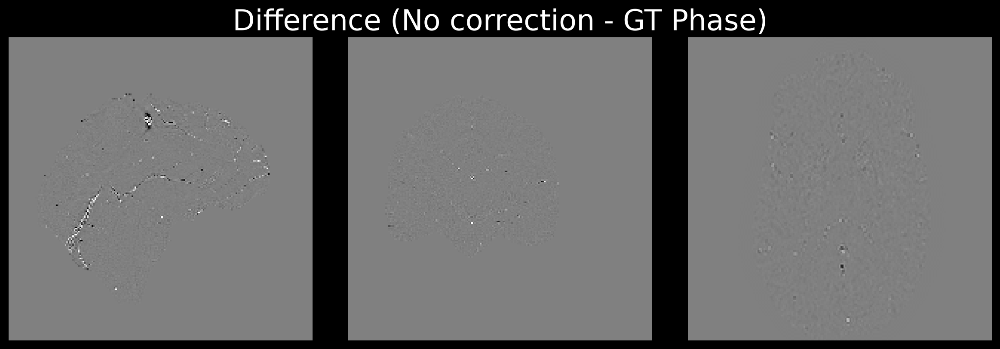

In [41]:

input_dirty = field["noise"]
imagesc3d2(input_dirty, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: dirty (ppm)")
input_fwd = clean_full
imagesc3d2(input_fwd * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: forward-simulated D*chi (ppm)")
imagesc3d2(input_dirty-input_fwd * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="input: forward-simulated D*chi (ppm)")
imagesc3d2(input_dirty-input_fwd * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="Difference (Correction - GT Phase)")
imagesc3d2(field["dirty"]-input_fwd * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="Difference (No correction - GT Phase)")

imagesc3d2(field["dirty"]-input_dirty * mask, tuple(x // 2 for x in N2), cmap='grey', contrast=[-0.05, 0.05], fig_num=2, rot_deg=[90, 90, 90], avg_size=0, title_fig="Difference (No correction - GT Phase)")

